# [GSE158406](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE158406)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2021-03-09
> - Modified: 2025-05-04

# 1. Experimental Design

> De novo DNA methyltransferase activity in colorectal cancer is directed towards H3K36me3 marked CpG island.
> - Masalmeh, R.H.A., Taglini, F., Rubio-Ramon, C. et al. De novo DNA methyltransferase activity in colorectal cancer is directed towards H3K36me3 marked CpG islands. Nat Commun 12, 694 (2021). https://doi.org/10.1038/s41467-020-20716-w.
> - RRBS, Ovation RRBS Methyl-Seq system kit (NuGen Technologies)
> - Illumina NextSeq 550, PE75

| Sample | Cell | Tissue | Genotype | Treatment | Replicate |
| - | - | - | - | - | - |
| Wild-type | HCT116 | Colonic epithelial cells | WT | 5-aza-2-deoxycytidine (3,6,13,16,22,28,40), untreated (40) | - |
| DNMT3B-KO | HCT116 | Colonic epithelial cells | DNMT3B-KO | 5-aza-2-deoxycytidine (0,3,6,13,16,22,28,40), untreated (40) | - |
| DNMT1-KO | HCT116 | Colonic epithelial cells | DNMT1-KO | 5-aza-2-deoxycytidine (0,3,6,13,16,22,28,40), untreated (40) | - |

> Notes:
> - 5-aza-dC (1 µM) for 24 h, followed by genomic DNA collection at indicated time points.

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(GenomicRanges))
suppressPackageStartupMessages(library(GenomeInfoDb))
suppressPackageStartupMessages(library(EnrichedHeatmap))
suppressPackageStartupMessages(library(RColorBrewer))
suppressPackageStartupMessages(library(viridis))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/rrbs_Hs_HCT116_DNMTs_GSE158406/02_output"

gtf_file <- "~/reference/Homo_sapiens/hg38/gencode.v48.annotation.gtf"

In [3]:
suppressPackageStartupMessages(library(BSgenome.Hsapiens.UCSC.hg38))
genome <- BSgenome.Hsapiens.UCSC.hg38

suppressPackageStartupMessages(library(TxDb.Hsapiens.UCSC.hg38.knownGene))
txdb <- TxDb.Hsapiens.UCSC.hg38.knownGene

# 2. Import Data

## 1). Import Bismark Cov

In [4]:
# Load Bismark coverage file as GRanges
load_bismark_cov <- function(
    file, cov = 5, keepStandardChr = TRUE, dropSex = TRUE, dropMito = TRUE) {

    gr <- data.table::fread(
        file, header = FALSE, sep = "\t", 
        col.names = c("chr", "start", "end", "meth", "numCs", "numTs")) |>
        dplyr::filter((numCs + numTs) >= cov) |>
        GRanges()

    # ---- Keep only standard chromosomes (optional) ----
    if (keepStandardChr) {
        gr <- GenomeInfoDb::keepStandardChromosomes(
            gr, pruning.mode = "coarse")
    }

    # ---- Remove sex chromosomes (optional) ----
    if (dropSex) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrX", "chrY"), pruning.mode = "coarse")
    }

    # ---- Remove mitochondrial DNA (optional) ----
    if (dropMito) {
        gr <- GenomeInfoDb::dropSeqlevels(
            gr, c("chrM", "M", "MT"), pruning.mode = "coarse")
    }

    return(gr)
}

In [6]:
file_pattern <- "(.*)\\.CpG_report\\.merged_CpG_evidence\\.cov\\.gz$"

cov_files <- file.path(data_dir, "04_bismark") |>
    list.files(pattern = file_pattern, full.names = TRUE) |>
    set_names(~ sub(file_pattern, "\\1", basename(.x)))

length(cov_files)

[1] 25

In [7]:
coldata <- tibble(sample = names(cov_files)) |>
    separate(
        sample, into = c("Cell", "Gene", "Genotype", "Treatment", "Time"),
        sep = "_", remove = FALSE) |>
    mutate(
        Gene = factor(Gene, levels = c("DNMTs", "DNMT1", "DNMT3B")),
        Genotype = factor(Genotype, levels = c("WT", "KO")),
        Treatment = factor(Treatment, levels = c("5aza", "control")),
        Time = factor(Time, levels = c(
            "d0", "d3", "d6", "d13", "d16", "d22", "d28", "d40")),
        Group = factor(interaction(Gene, Genotype, sep = "-")),
        Condition = factor(interaction(Treatment, Time, sep = "-"))) |>
    column_to_rownames("sample") |>
    arrange(Group, Condition)

head(coldata)

,Cell,Gene,Genotype,Treatment,Time,Group,Condition
,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
HCT116_DNMTs_WT_5aza_d3,HCT116,DNMTs,WT,5aza,d3,DNMTs-WT,5aza-d3
HCT116_DNMTs_WT_5aza_d6,HCT116,DNMTs,WT,5aza,d6,DNMTs-WT,5aza-d6
HCT116_DNMTs_WT_5aza_d13,HCT116,DNMTs,WT,5aza,d13,DNMTs-WT,5aza-d13
HCT116_DNMTs_WT_5aza_d16,HCT116,DNMTs,WT,5aza,d16,DNMTs-WT,5aza-d16
HCT116_DNMTs_WT_5aza_d22,HCT116,DNMTs,WT,5aza,d22,DNMTs-WT,5aza-d22
HCT116_DNMTs_WT_5aza_d28,HCT116,DNMTs,WT,5aza,d28,DNMTs-WT,5aza-d28


In [8]:
meth_list <- lapply(cov_files, cov = 5, load_bismark_cov, dropSex = FALSE)
meth_list <- meth_list[rownames(coldata)]

meth_list[1]

$HCT116_DNMTs_WT_5aza_d3
GRanges object with 2738031 ranges and 3 metadata columns:
            seqnames            ranges strand |      meth     numCs     numTs
               <Rle>         <IRanges>  <Rle> | <numeric> <integer> <integer>
        [1]     chr1       10525-10526      * |   55.4974       106        85
        [2]     chr1       10542-10543      * |   53.9267       103        88
        [3]     chr1       10563-10564      * |   54.4503       104        87
        [4]     chr1       10571-10572      * |   55.7895       106        84
        [5]     chr1       10577-10578      * |   55.4974       106        85
        ...      ...               ...    ... .       ...       ...       ...
  [2738027]     chrY 56879970-56879971      * |   20.0000        17        68
  [2738028]     chrY 56886894-56886895      * |   50.0000        14        14
  [2738029]     chrY 56886917-56886918      * |   28.5714         8        20
  [2738030]     chrY 56886944-56886945      * |   17.8571 

# 3. Evaluate Library Quality

In [9]:
suppressPackageStartupMessages(library(ggridges))

Picking joint bandwidth of 1.63



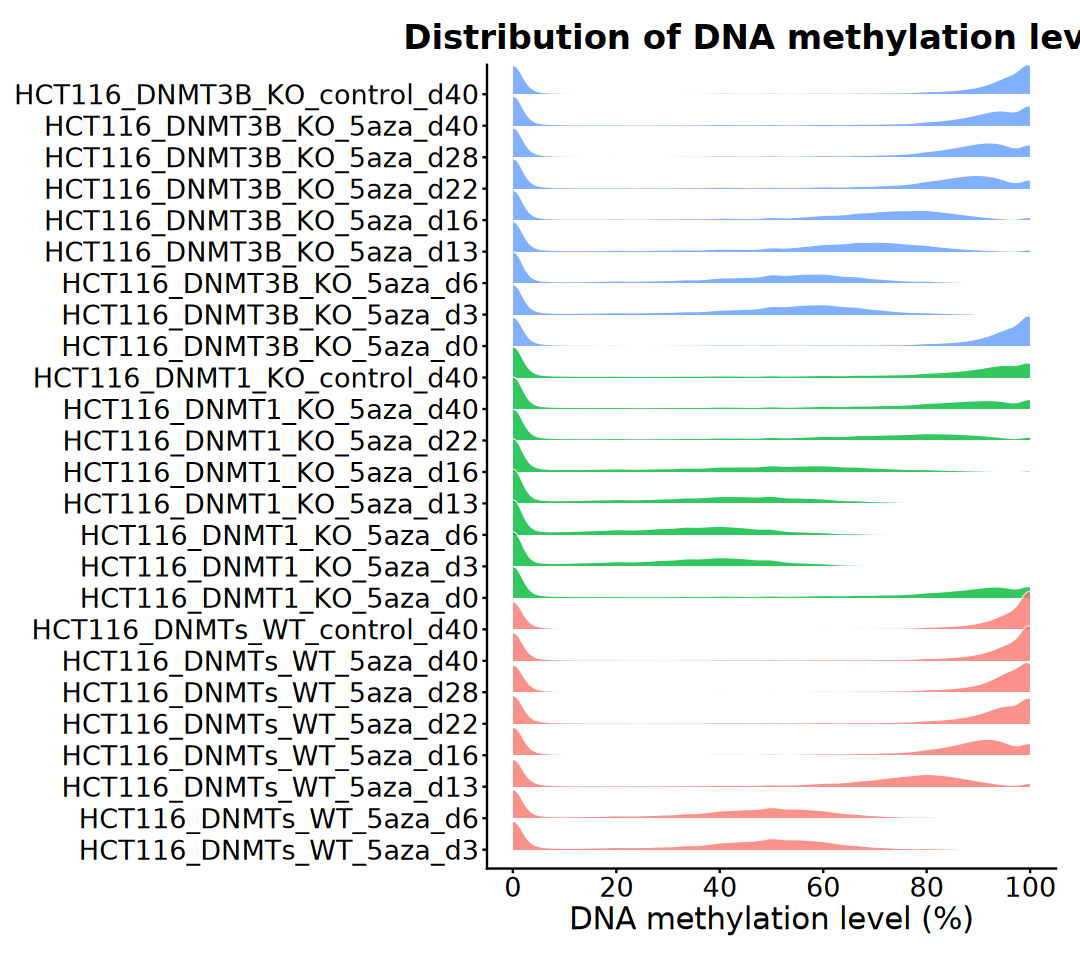

In [10]:
options(repr.plot.width = 9, repr.plot.height = 8)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    dplyr::select(sample, meth) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, rownames(coldata))) |>
    ggplot(aes(x = meth, y = sample)) +
        geom_density_ridges(
            aes(fill = Group), scale = 1.2, rel_min_height = 0.01, 
            alpha = 0.8, color = "white", linewidth = 0.2) +
        scale_x_continuous(breaks = seq(0, 100, 20), limits = c(0, 100)) +
        scale_color_brewer(palette = "Set1") +
        labs(
            title = "Distribution of DNA methylation levels",
            x = "DNA methylation level (%)", y = NULL) +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.position = "none",
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

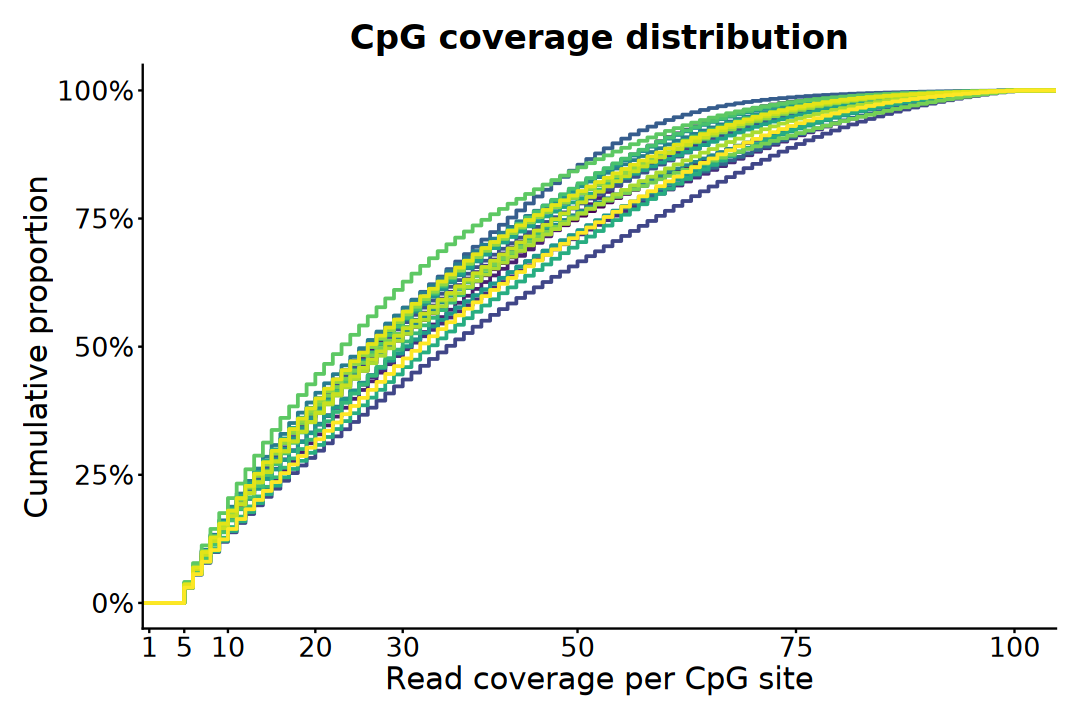

In [11]:
options(repr.plot.width = 9, repr.plot.height = 6)

map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    mutate(
        coverage = numCs + numTs, 
        sample = factor(sample, rownames(coldata))) |>
    dplyr::select(sample, coverage) |>
    dplyr::filter(!is.na(coverage), coverage > 0, coverage <= 100) |>
    ggplot(aes(x = coverage, color = sample)) +
        stat_ecdf(linewidth = 0.8) +
        scale_x_continuous(breaks = c(1, 5, 10, 20, 30, 50, 75, 100)) +
        scale_y_continuous(labels = scales::label_percent()) +
        scale_color_viridis_d(option = "D") +
        labs(
            title = "CpG coverage distribution",
            x = "Read coverage per CpG site",
            y = "Cumulative proportion", color = "Sample") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            legend.position = "none",
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

In [12]:
coverage_df <- map_df(meth_list, ~ as.data.frame(mcols(.x)), .id = "sample") |>
    mutate(
        coverage = numCs + numTs,
        sample = factor(sample, rownames(coldata))) |>
    group_by(sample) |>
    summarise(
        total_cpg = n(),
        cov1 = sum(coverage >= 1) / n(),
        cov5 = sum(coverage >= 5) / n(),
        cov10 = sum(coverage >= 10) / n(),
        cov20 = sum(coverage >= 20) / n(),
        cov30 = sum(coverage >= 30) / n(),
        cov50 = sum(coverage >= 50) / n()) |>
    pivot_longer(
        cols = starts_with("cov"), 
        names_to = "threshold", values_to = "fraction") |>
    mutate(threshold = readr::parse_number(threshold))

head(coverage_df)

sample,total_cpg,threshold,fraction
<fct>,<int>,<dbl>,<dbl>
HCT116_DNMTs_WT_5aza_d3,2738031,1,1.0000000
HCT116_DNMTs_WT_5aza_d3,2738031,5,1.0000000
HCT116_DNMTs_WT_5aza_d3,2738031,10,0.8553669
HCT116_DNMTs_WT_5aza_d3,2738031,20,0.6515346
HCT116_DNMTs_WT_5aza_d3,2738031,30,0.4948282
HCT116_DNMTs_WT_5aza_d3,2738031,50,0.2630365


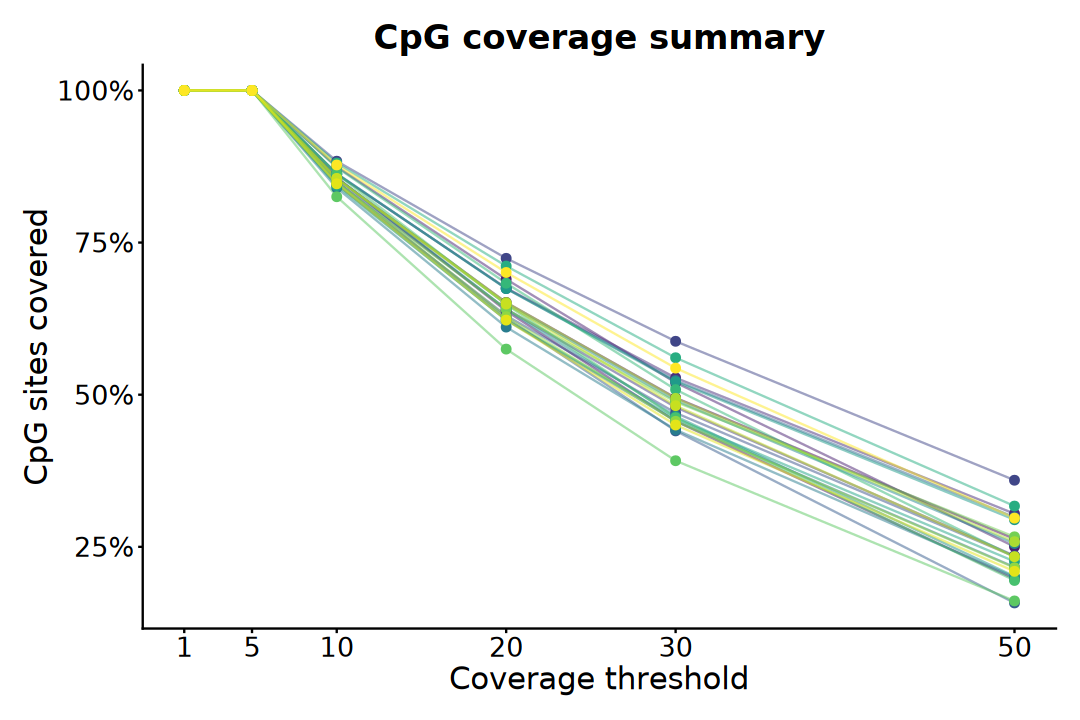

In [13]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(coverage_df, aes(
    x = threshold, y = fraction, color = sample, group = sample)) +
    geom_line(alpha = 0.5) + 
    geom_point(size = 2) +
    scale_x_continuous(breaks = c(1, 5, 10, 20, 30, 50)) +
    scale_y_continuous(labels = scales::label_percent()) +
    scale_color_viridis_d(option = "D") +
    labs(
        title = "CpG coverage summary",
        x = "Coverage threshold", y = "CpG sites covered") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

# 4. Global Methylation

## 1). Standard Plot

In [14]:
plot_df <- data.frame(
    sample = names(meth_list),
    number = sapply(meth_list, length),
    mean = sapply(meth_list, \(gr) mean(mcols(gr)$meth))) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    column_to_rownames("sample")

head(plot_df)

,number,mean,Cell,Gene,Genotype,Treatment,Time,Group,Condition
,<int>,<dbl>,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
HCT116_DNMTs_WT_5aza_d3,2738031,34.76281,HCT116,DNMTs,WT,5aza,d3,DNMTs-WT,5aza-d3
HCT116_DNMTs_WT_5aza_d6,2826066,34.26095,HCT116,DNMTs,WT,5aza,d6,DNMTs-WT,5aza-d6
HCT116_DNMTs_WT_5aza_d13,2834648,52.53492,HCT116,DNMTs,WT,5aza,d13,DNMTs-WT,5aza-d13
HCT116_DNMTs_WT_5aza_d16,2716898,59.81666,HCT116,DNMTs,WT,5aza,d16,DNMTs-WT,5aza-d16
HCT116_DNMTs_WT_5aza_d22,2648993,62.70034,HCT116,DNMTs,WT,5aza,d22,DNMTs-WT,5aza-d22
HCT116_DNMTs_WT_5aza_d28,2844827,64.17930,HCT116,DNMTs,WT,5aza,d28,DNMTs-WT,5aza-d28


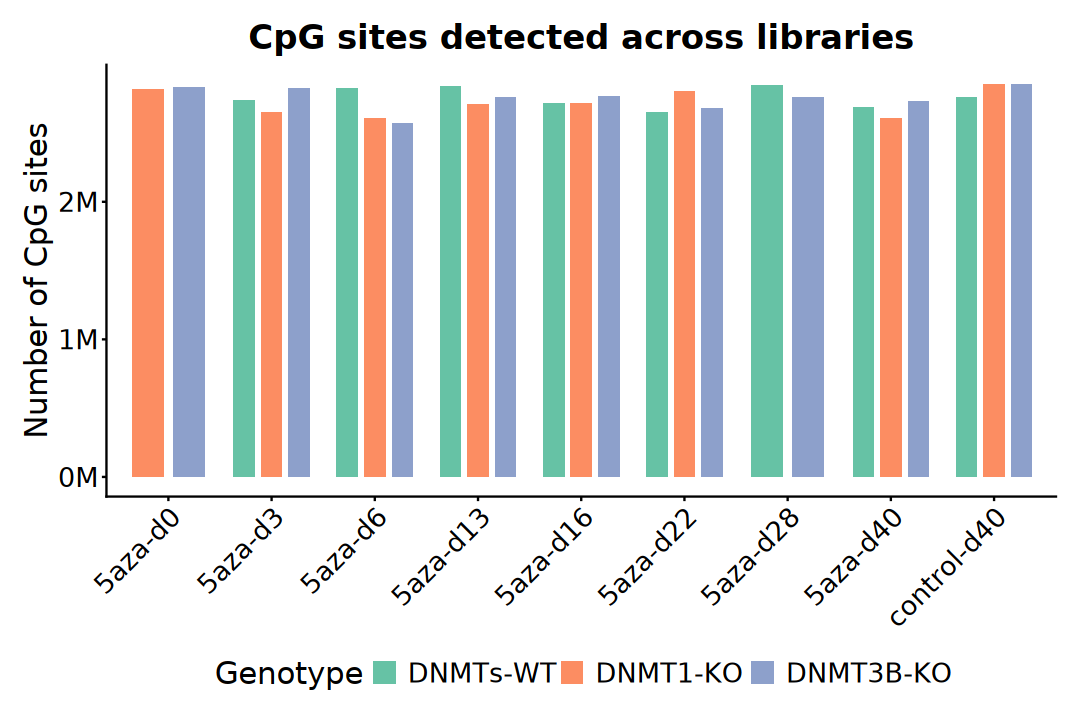

In [15]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Condition, y = number, group = Group)) +
    geom_bar(
        aes(fill = Group), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M")) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG sites detected across libraries", 
        x = NULL, y = "Number of CpG sites", 
        fill = "Genotype") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

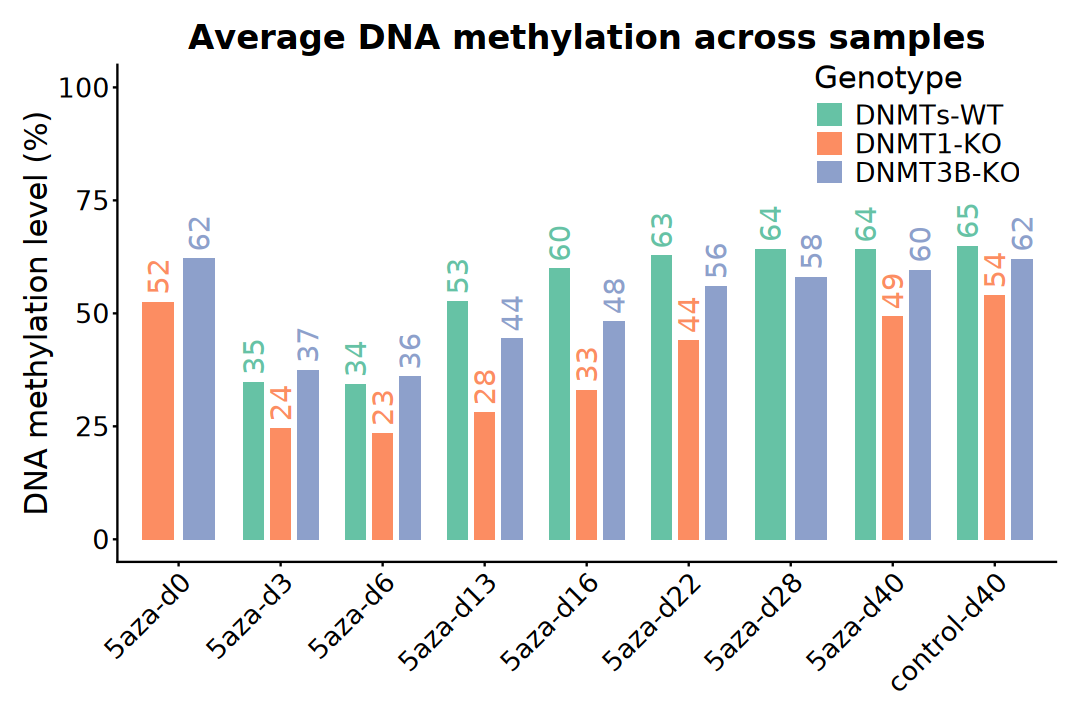

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Condition, y = mean, group = Group)) +
    geom_bar(
        aes(fill = Group), stat = "identity", 
        position = position_dodge(width = 0.8), 
        width = 0.6, linewidth = 1.5) +
    geom_text(
        aes(color = Group, label = sprintf("%.0f", round(mean, 2))),
        position = position_dodge(width = 0.8),
        angle = 90, vjust = 0.5, hjust = -0.2, size = 6) +
    coord_cartesian(ylim = c(0, 100)) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "Average DNA methylation across samples",
        x = NULL, y = "DNA methylation level (%)", 
        color = "Genotype", fill = "Genotype") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "inside",
        legend.position.inside = c(0.85, 0.88),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

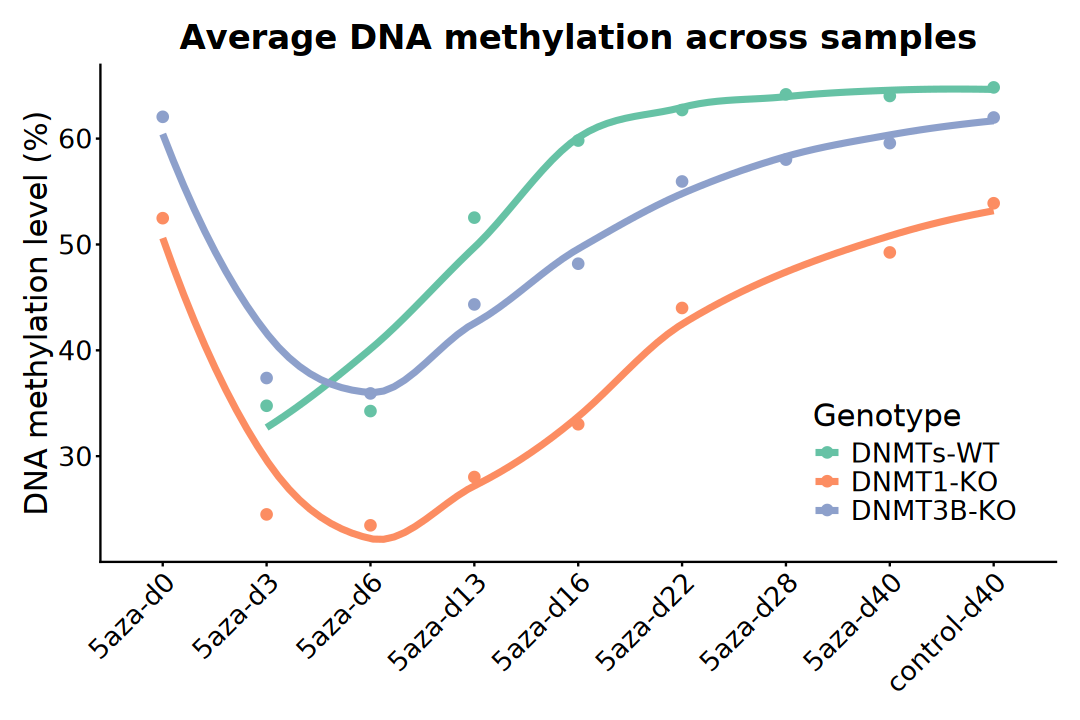

In [17]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Condition, y = mean, group = Group)) +
    geom_point(aes(color = Group), size = 2.5) +
    geom_smooth(
        aes(color = Group), formula = 'y ~ x', method = 'loess', 
        se = FALSE, linewidth = 1.5) +
    scale_color_brewer(palette = "Set2") +
    labs(
        title = "Average DNA methylation across samples",
        x = NULL, y = "DNA methylation level (%)", 
        color = "Genotype") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "inside",
        legend.position.inside = c(0.85, 0.20),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

## 2). Boxplot

In [18]:
plot_df <- map_dfr(meth_list, ~ tibble(
    meth = mcols(.x)$meth), .id = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample")

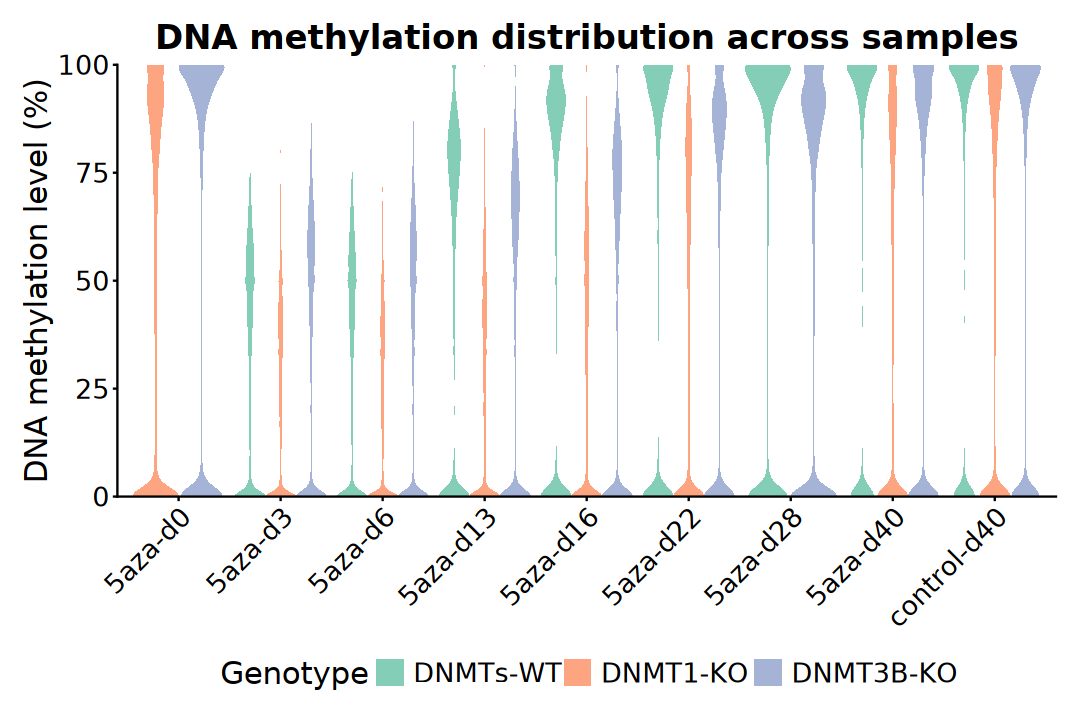

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Condition, y = meth, fill = Group)) +
    geom_violin(trim = TRUE, scale = "width", color = NA, alpha = 0.8) +
    scale_y_continuous(limits = c(0, 100), expand = c(0, 0)) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "DNA methylation distribution across samples",
        x = NULL, y = "DNA methylation level (%)", 
        fill = "Genotype") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

In [20]:
suppressPackageStartupMessages(library(gghalves))

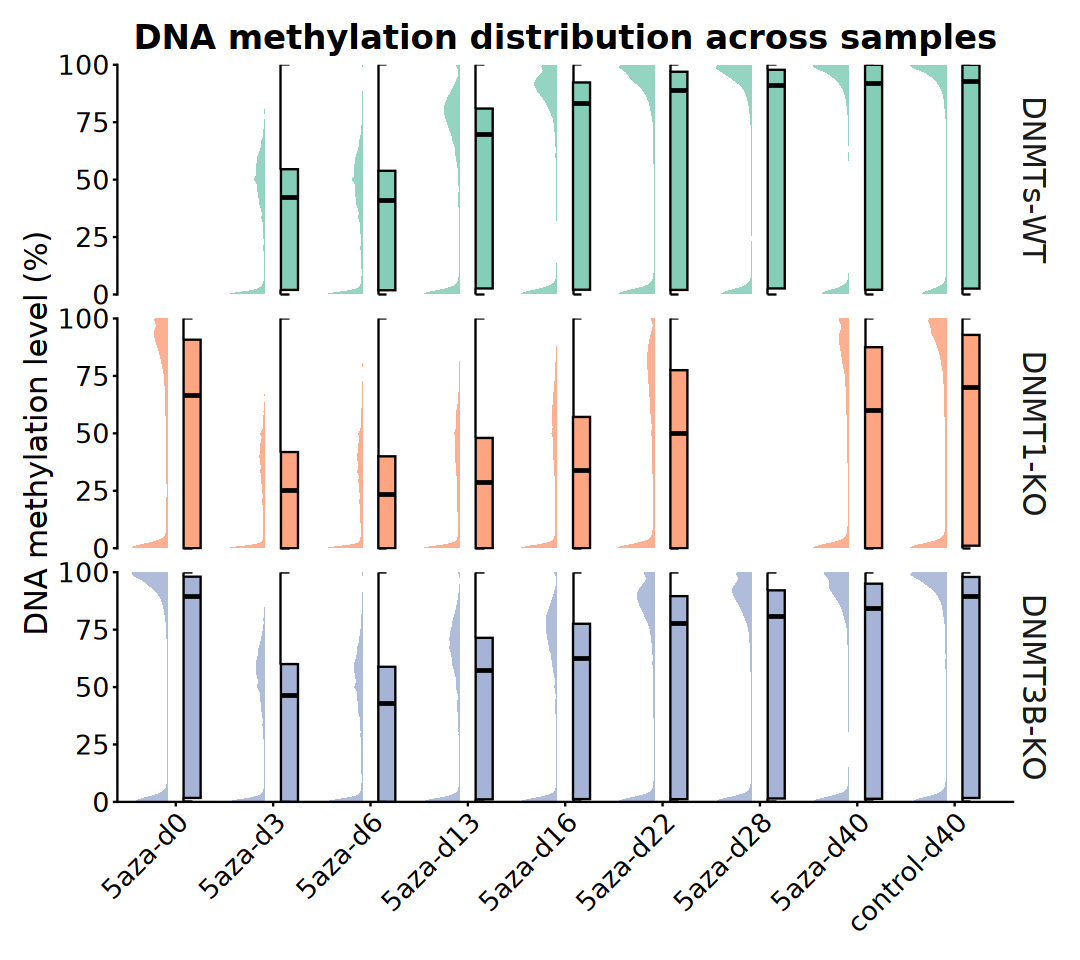

In [21]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = Condition, y = meth, fill = Group)) +
    geom_half_violin(
        aes(group = interaction(Condition, Group)), 
        side = "l", trim = TRUE, scale = "width", alpha = 0.7,
        color = NA, position = position_nudge(x = -0.08)) +
    geom_half_boxplot(
        aes(group = interaction(Condition, Group)),
        side = "r", width = 0.35, outlier.shape = NA, alpha = 0.8,
        color = "black", position = position_nudge(x = 0.08)) +
    facet_wrap(~ Group, ncol = 1, strip.position = "right") +
    scale_y_continuous(limits = c(0, 100), expand = c(0, 0)) +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "DNA methylation distribution across samples",
        x = NULL, y = "DNA methylation level (%)", 
        fill = "Genotype") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(),
        strip.placement = "outside",
        panel.spacing.y = unit(1, "lines"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "none",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

## 3). Metagene Profile

In [22]:
gtf <- import(gtf_file)

GENES <- subset(
    gtf, type == "gene" & gene_type == "protein_coding",
    select = c("gene_id", "gene_name")
)

PROMOTERS <- promoters(GENES, upstream = 2000, downstream = 500)

In [23]:
CGI <- read.table(
    "~/reference/Homo_sapiens/hg38/ucsc/cpgIslandExt.txt", 
    header = FALSE, sep = "\t", col.names = c(
        "bin", "chr", "start", "end", "names", "length", 
        "cpgNum", "gcNum", "perCpg", "perGc", "obsExp")) |>
    dplyr::filter(length > 300) |>
    GRanges() |>
    keepStandardChromosomes(pruning.mode = "coarse")

In [24]:
PROMOTERS$CGI_status <- ifelse(
    overlapsAny(PROMOTERS, CGI), "CGI", "non_CGI") |> 
    factor(levels = c("CGI", "non_CGI"))
table(PROMOTERS$CGI_status)

CGI$Promoter_status <- ifelse(
    overlapsAny(CGI, PROMOTERS), "Promoter", "non_Promoter") |> 
    factor(levels = c("Promoter", "non_Promoter"))
table(CGI$Promoter_status)


    CGI non_CGI 
  12398    7698 


    Promoter non_Promoter 
       10957        11115 

### a). Genes

In [25]:
# ~ 15 min
gene_mat_List <- lapply(
    meth_list, normalizeToMatrix, GENES, value_column = "meth", 
    extend = 2000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.4, background = NA, smooth = FALSE)

In [26]:
position_index <- c(
    paste0("u", seq_len(40)), 
    paste0("t", seq_len(53)), 
    paste0("d", seq_len(40))
)

plot_df <- gene_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(
        pos = factor(pos, levels = position_index), 
        sample = factor(sample, levels = names(meth_list)))

head(plot_df)

sample,pos,meth,Cell,Gene,Genotype,Treatment,Time,Group,Condition
<fct>,<fct>,<dbl>,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
HCT116_DNMTs_WT_5aza_d3,u1,40.94998,HCT116,DNMTs,WT,5aza,d3,DNMTs-WT,5aza-d3
HCT116_DNMTs_WT_5aza_d3,u2,40.00508,HCT116,DNMTs,WT,5aza,d3,DNMTs-WT,5aza-d3
HCT116_DNMTs_WT_5aza_d3,u3,39.88401,HCT116,DNMTs,WT,5aza,d3,DNMTs-WT,5aza-d3
HCT116_DNMTs_WT_5aza_d3,u4,39.76052,HCT116,DNMTs,WT,5aza,d3,DNMTs-WT,5aza-d3
HCT116_DNMTs_WT_5aza_d3,u5,39.72494,HCT116,DNMTs,WT,5aza,d3,DNMTs-WT,5aza-d3
HCT116_DNMTs_WT_5aza_d3,u6,39.72229,HCT116,DNMTs,WT,5aza,d3,DNMTs-WT,5aza-d3


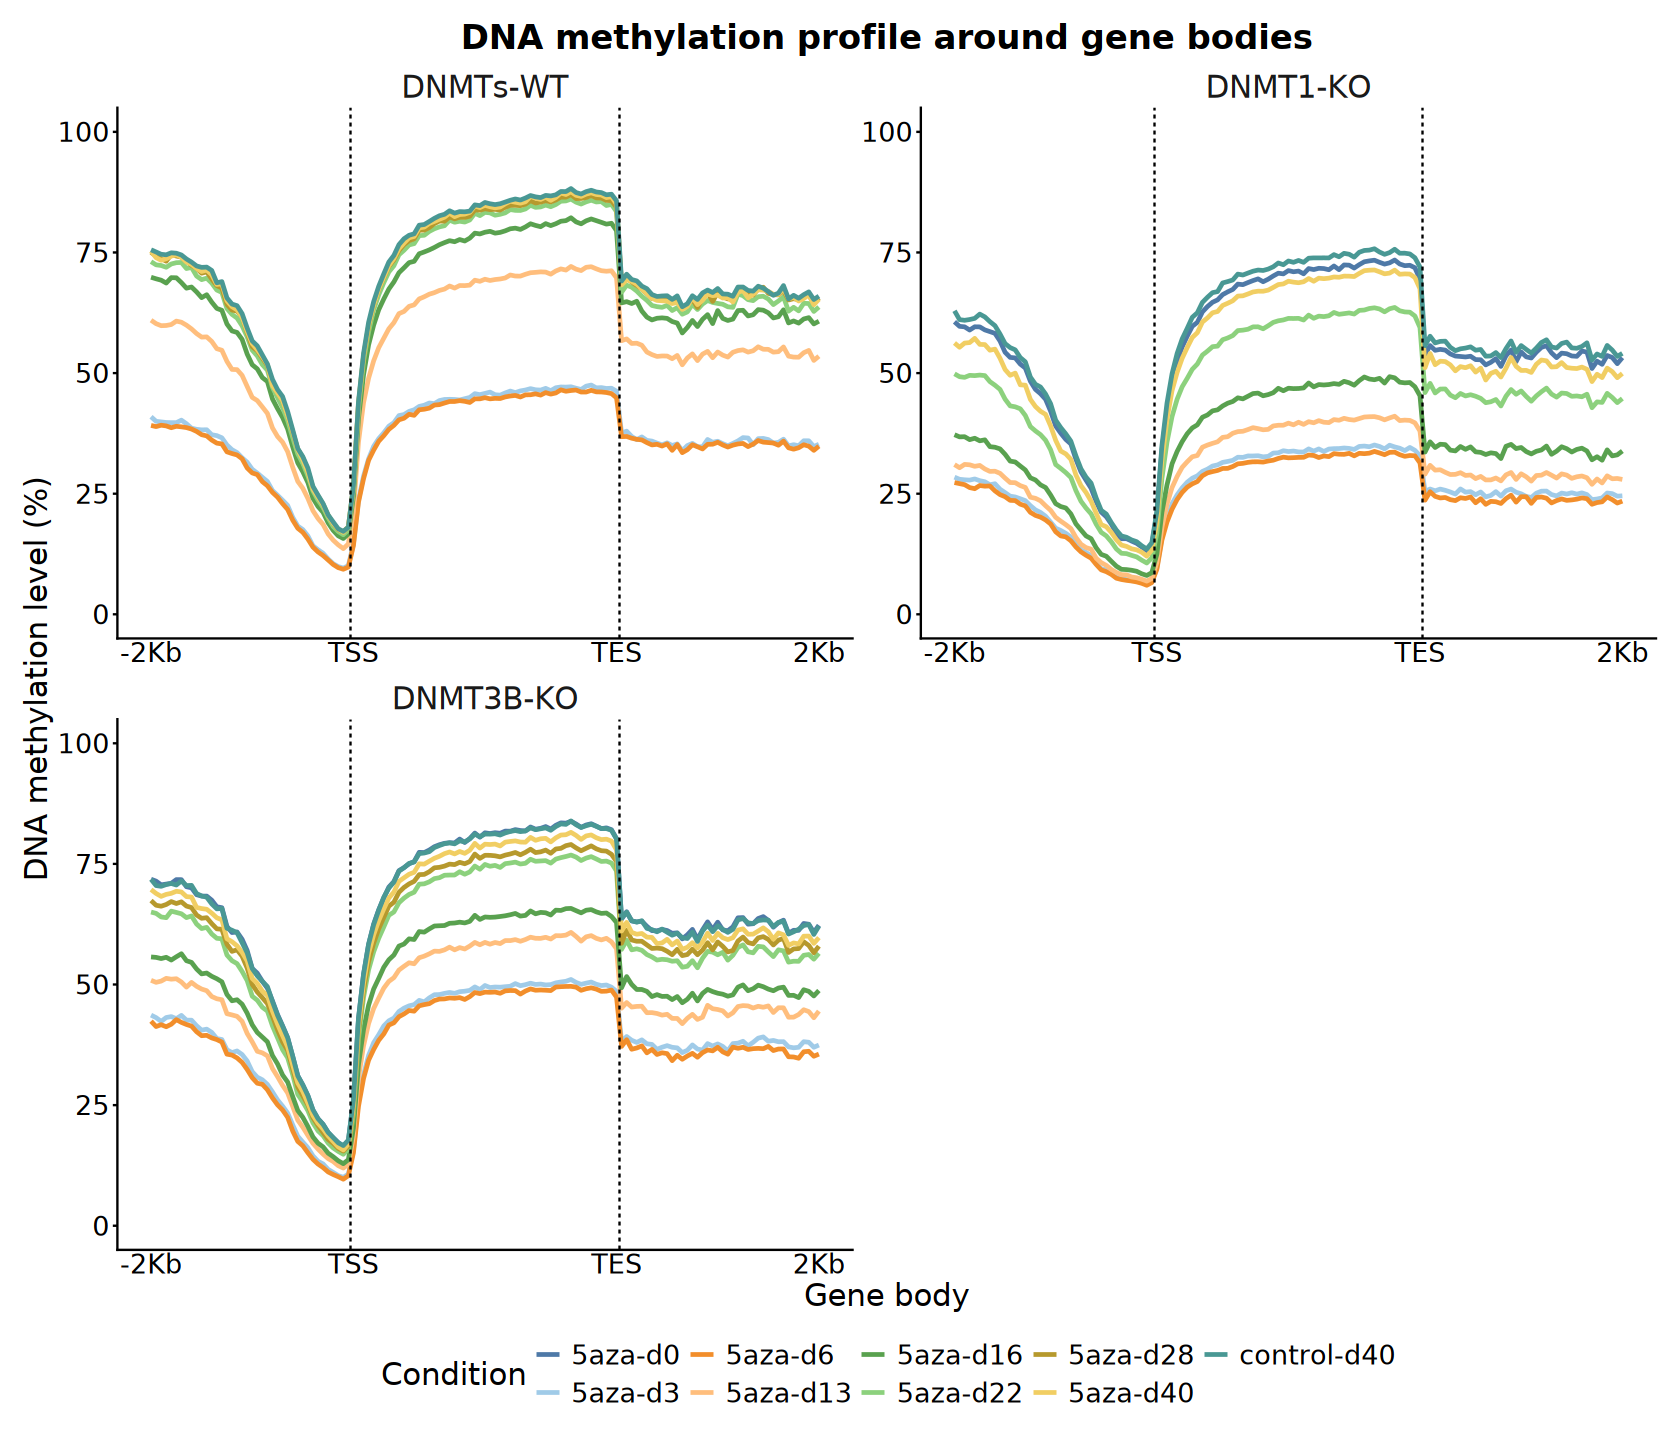

In [27]:
options(repr.plot.width = 14, repr.plot.height = 12)

ggplot(plot_df, aes(x = pos, y = meth, color = Condition, group = Condition)) +
    geom_line(linewidth = 1, alpha = 1, na.rm = TRUE) +
    geom_vline(xintercept = 40.5, linetype = 2) +
    geom_vline(xintercept = 93.5, linetype = 2) +
    facet_wrap( ~ Group, scales = "free", ncol = 2) +
    scale_x_discrete(
        breaks = c("u1", "t1", "t53", "d40"), expand = c(0.05, 0.05),
        labels = c("u1" = "-2Kb", "t1" = "TSS", "t53" = "TES", "d40" = "2Kb")) +
    coord_cartesian(ylim = c(0, 100)) +
    # scale_color_viridis_d(option = "turbo") +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profile around gene bodies", 
        x = "Gene body", y = "DNA methylation level (%)", 
        color = "Condition") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        strip.text = element_text(size = 18), 
        strip.background = element_blank(), 
        strip.placement = "outside", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

### b). CGI

In [28]:
# ~ 15 min
cgi_mat_List <- lapply(
    meth_list, normalizeToMatrix, CGI, value_column = "meth",
    extend = 4000, mean_mode = "absolute", w = 50, 
    target_ratio = 0.3, background = NA, smooth = FALSE)

In [29]:
position_index <- c(
    paste0("u", seq_len(80)), 
    paste0("t", seq_len(69)), 
    paste0("d", seq_len(80))
)

plot_df <- cgi_mat_List |>
    lapply(colMeans, na.rm = TRUE) |>
    bind_rows(.id = "sample") |>
    pivot_longer(cols = -sample, names_to = "pos", values_to = "meth") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(
        pos = factor(pos, levels = position_index), 
        sample = factor(sample, levels = names(meth_list)))

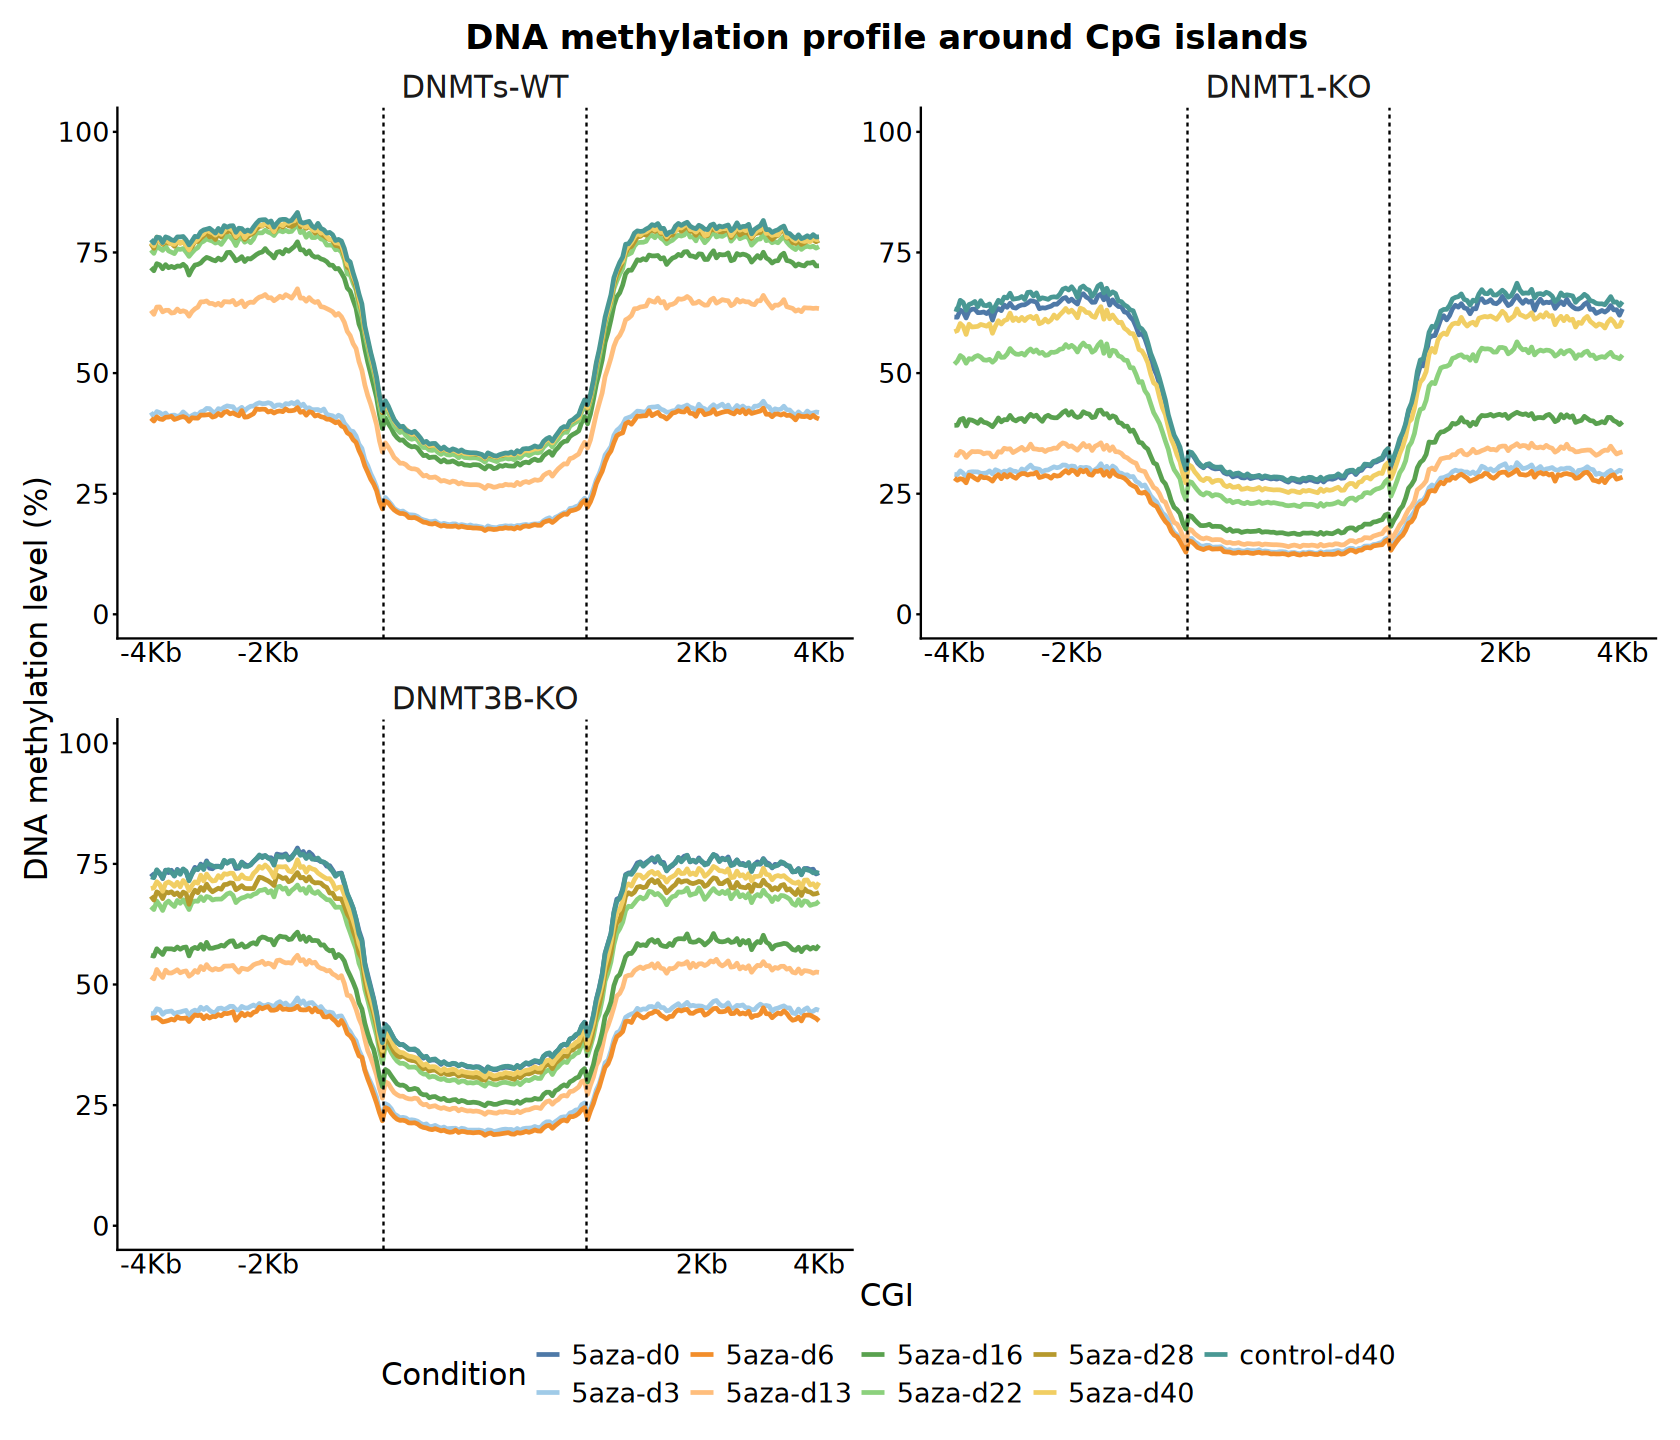

In [30]:
options(repr.plot.width = 14, repr.plot.height = 12)

ggplot(plot_df, aes(x = pos, y = meth, color = Condition, group = Condition)) +
    geom_line(linewidth = 1, alpha = 1, na.rm = TRUE) +
    geom_vline(xintercept = 80.5, linetype = 2) +
    geom_vline(xintercept = 149.5, linetype = 2) +
    facet_wrap( ~ Group, scales = "free", ncol = 2) +
    scale_x_discrete(
        breaks = c("u1", "u41", "d40", "d80"), 
        labels = c(
            "u1" = "-4Kb", "u41" = "-2Kb", "d40" = "2Kb", "d80" = "4Kb"),
        expand = c(0.05, 0.05)) +
    coord_cartesian(ylim = c(0, 100)) +
    # scale_color_viridis_d(option = "turbo") +
    ggthemes::scale_color_tableau(palette = "Tableau 20") +
    guides(color = guide_legend(nrow = 2)) +
    labs(
        title = "DNA methylation profile around CpG islands",
        x = "CGI", y = "DNA methylation level (%)", 
        color = "Condition") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        strip.text = element_text(size = 18), 
        strip.background = element_blank(), 
        strip.placement = "outside", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16), 
        legend.position = "bottom", 
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16), 
        axis.ticks.x = element_blank())

### Ridges plot

In [31]:
get_region_data <- function(
    gr, region, sample_id, method = c("mean", "ratio"),
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    hits <- findOverlaps(gr, region, ignore.strand = TRUE)
    region_mean <- rep(NA_real_, length(region))

    if (length(hits) == 0) {
        mcols(region)[[sample_id]] <- region_mean
        return(region)
    }

    cpg_idx <- queryHits(hits)
    region_idx <- subjectHits(hits)

    if (method == "mean") {
        vals <- mcols(gr)[[meth_col]]
        region_mean <- tapply(vals[cpg_idx], region_idx, mean, na.rm = TRUE)
        result <- rep(NA_real_, length(region))
        result[as.integer(names(region_mean))] <- region_mean
    } else {
        numCs <- mcols(gr)[[numCs_col]]
        numTs <- mcols(gr)[[numTs_col]]
        sumCs <- tapply(numCs[cpg_idx], region_idx, sum, na.rm = TRUE)
        sumTs <- tapply(numTs[cpg_idx], region_idx, sum, na.rm = TRUE)
        region_mean <- sumCs / (sumCs + sumTs) * 100
        result <- rep(NA_real_, length(region))
        result[as.integer(names(region_mean))] <- region_mean
    }
    mcols(region)[[sample_id]] <- result
    return(region)
}

In [32]:
region_mat <- Reduce(function(region, sample) {
    get_region_data(
        gr = meth_list[[sample]], region = region, sample_id = sample,
        method = "mean", meth_col = "meth")
    }, names(meth_list), init = CGI)

In [33]:
plot_df <- region_mat |> mcols() |> as.data.frame() |>
    dplyr::select(Promoter_status, names(meth_list)) |>
    pivot_longer(
        cols = - Promoter_status, names_to = "sample", values_to = "meth") |>
    filter(!is.na(meth)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = names(meth_list)))

head(plot_df)

Promoter_status,sample,meth,Cell,Gene,Genotype,Treatment,Time,Group,Condition
<fct>,<fct>,<dbl>,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>
non_Promoter,HCT116_DNMTs_WT_5aza_d3,39.91546,HCT116,DNMTs,WT,5aza,d3,DNMTs-WT,5aza-d3
non_Promoter,HCT116_DNMTs_WT_5aza_d6,36.56126,HCT116,DNMTs,WT,5aza,d6,DNMTs-WT,5aza-d6
non_Promoter,HCT116_DNMTs_WT_5aza_d13,71.85961,HCT116,DNMTs,WT,5aza,d13,DNMTs-WT,5aza-d13
non_Promoter,HCT116_DNMTs_WT_5aza_d16,91.66667,HCT116,DNMTs,WT,5aza,d16,DNMTs-WT,5aza-d16
non_Promoter,HCT116_DNMTs_WT_5aza_d22,85.94862,HCT116,DNMTs,WT,5aza,d22,DNMTs-WT,5aza-d22
non_Promoter,HCT116_DNMTs_WT_5aza_d28,88.09524,HCT116,DNMTs,WT,5aza,d28,DNMTs-WT,5aza-d28


Picking joint bandwidth of 2.39

Picking joint bandwidth of 4.72



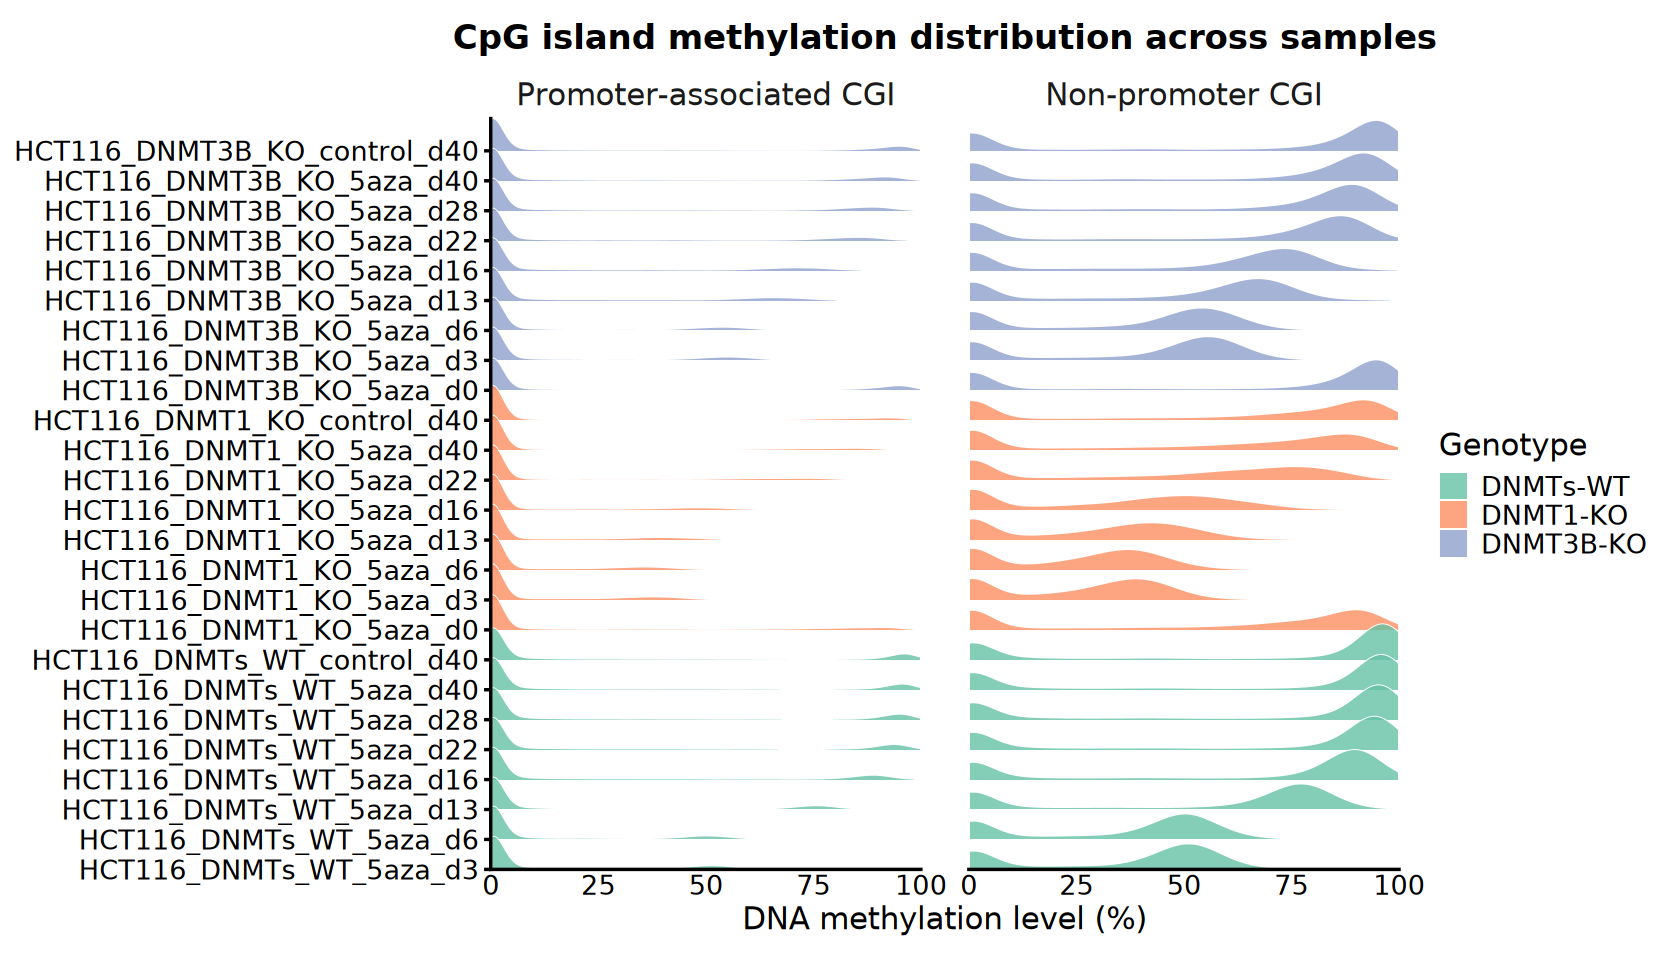

In [34]:
options(repr.plot.width = 14, repr.plot.height = 8)

ggplot(plot_df, aes(x = meth, y = sample)) +
    geom_density_ridges(
            aes(fill = Group), scale = 1.2, rel_min_height = 0.01, 
            alpha = 0.8, color = "white", linewidth = 0.2) +
    facet_wrap(~ Promoter_status, labeller = labeller(
        Promoter_status = c(
            "Promoter" = "Promoter-associated CGI",
            "non_Promoter" = "Non-promoter CGI"))) +
    scale_x_continuous(limits = c(0, 100), expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0)) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG island methylation distribution across samples",
        x = "DNA methylation level (%)", y = NULL, 
        fill = "Genotype") +
    theme_classic(base_size = 16) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing = unit(2, "lines"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(), 
        strip.placement = "outside",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16),
        axis.ticks.x = element_blank())

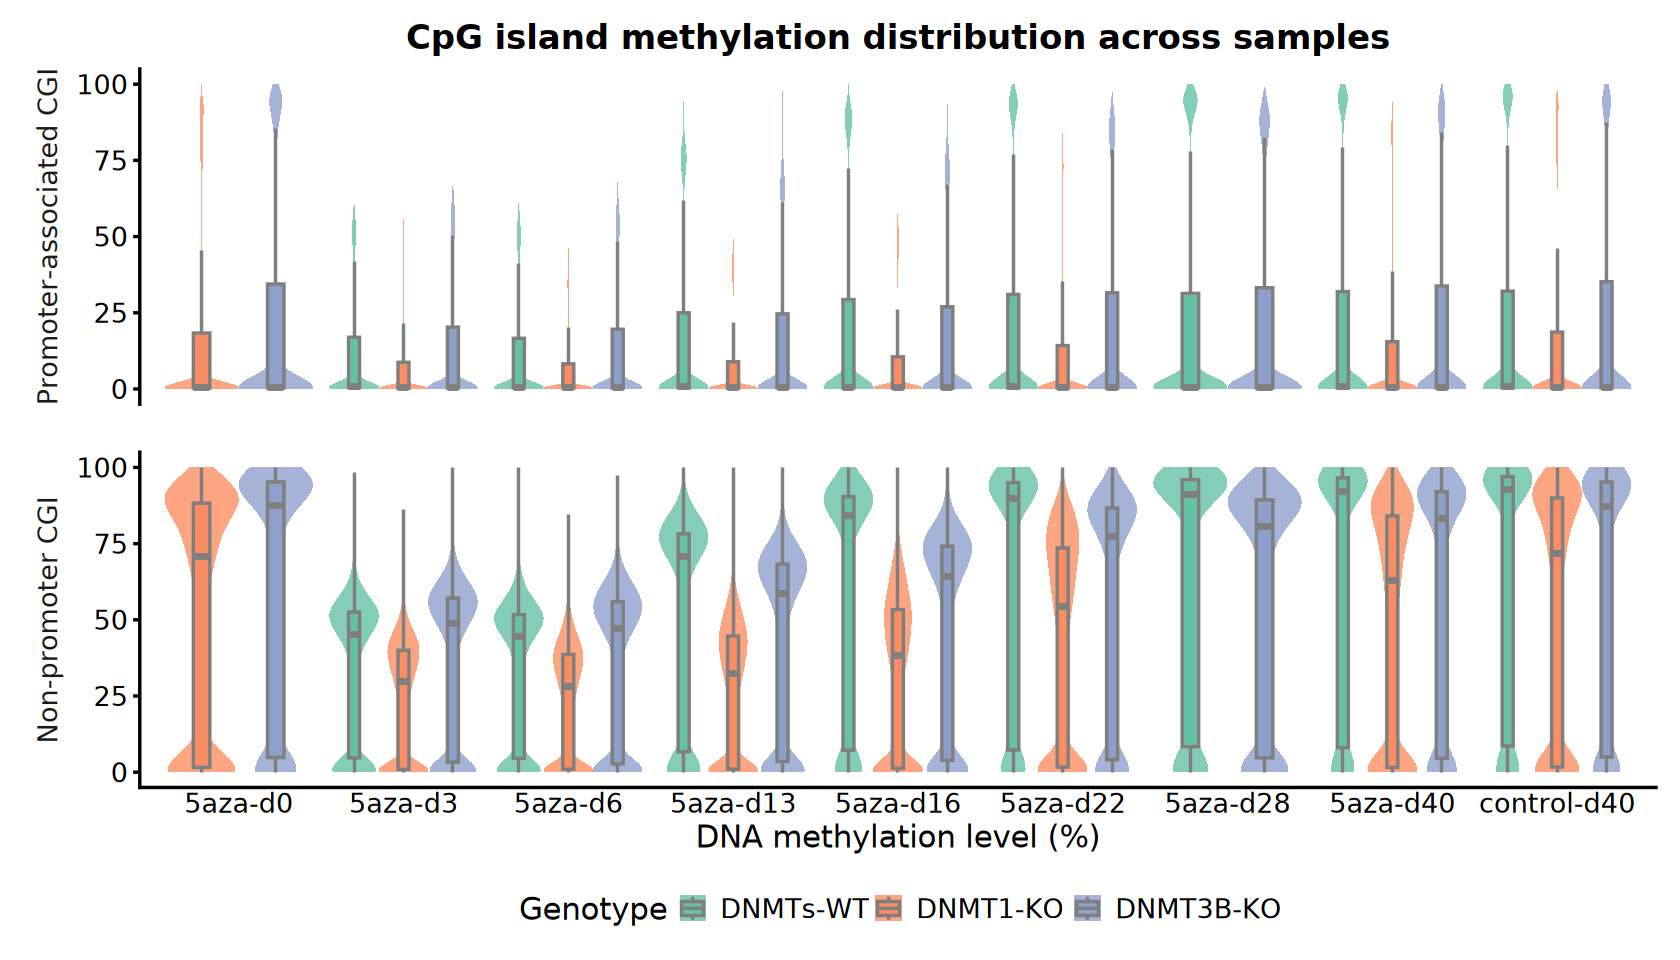

In [35]:
options(repr.plot.width = 14, repr.plot.height = 8)

ggplot(plot_df, aes(x = Condition, y = meth, fill = Group)) +
    geom_violin(
        trim = TRUE, scale = "width", color = NA, alpha = 0.8) +
    geom_boxplot(
        width = 0.2, outlier.shape = NA, color = "grey50",
        position = position_dodge(width = 0.9)) +
    facet_wrap(~ Promoter_status, ncol = 1, strip.position = "left",
        labeller = labeller(Promoter_status = c(
            "Promoter" = "Promoter-associated CGI",
            "non_Promoter" = "Non-promoter CGI"))) +
    # scale_x_continuous(limits = c(0, 100), expand = c(0, 0)) +
    # scale_y_discrete(expand = c(0, 0)) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG island methylation distribution across samples",
        x = "DNA methylation level (%)", y = NULL, 
        fill = "Genotype") +
    theme_classic(base_size = 16) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing = unit(2, "lines"),
        strip.text = element_text(size = 16),
        strip.background = element_blank(), 
        strip.placement = "outside",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16),
        axis.ticks.x = element_blank())

In [36]:
region_mat <- Reduce(function(region, sample) {
    get_region_data(
        gr = meth_list[[sample]], region = region, sample_id = sample,
        method = "mean", meth_col = "meth")
    }, names(meth_list), init = PROMOTERS)

In [37]:
plot_df <- region_mat |> mcols() |> as.data.frame() |>
    dplyr::select(CGI_status, names(meth_list)) |>
    pivot_longer(
        cols = - CGI_status, names_to = "sample", values_to = "meth") |>
    filter(!is.na(meth)) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(sample = factor(sample, levels = names(meth_list)))

Picking joint bandwidth of 2.38

Picking joint bandwidth of 5.02



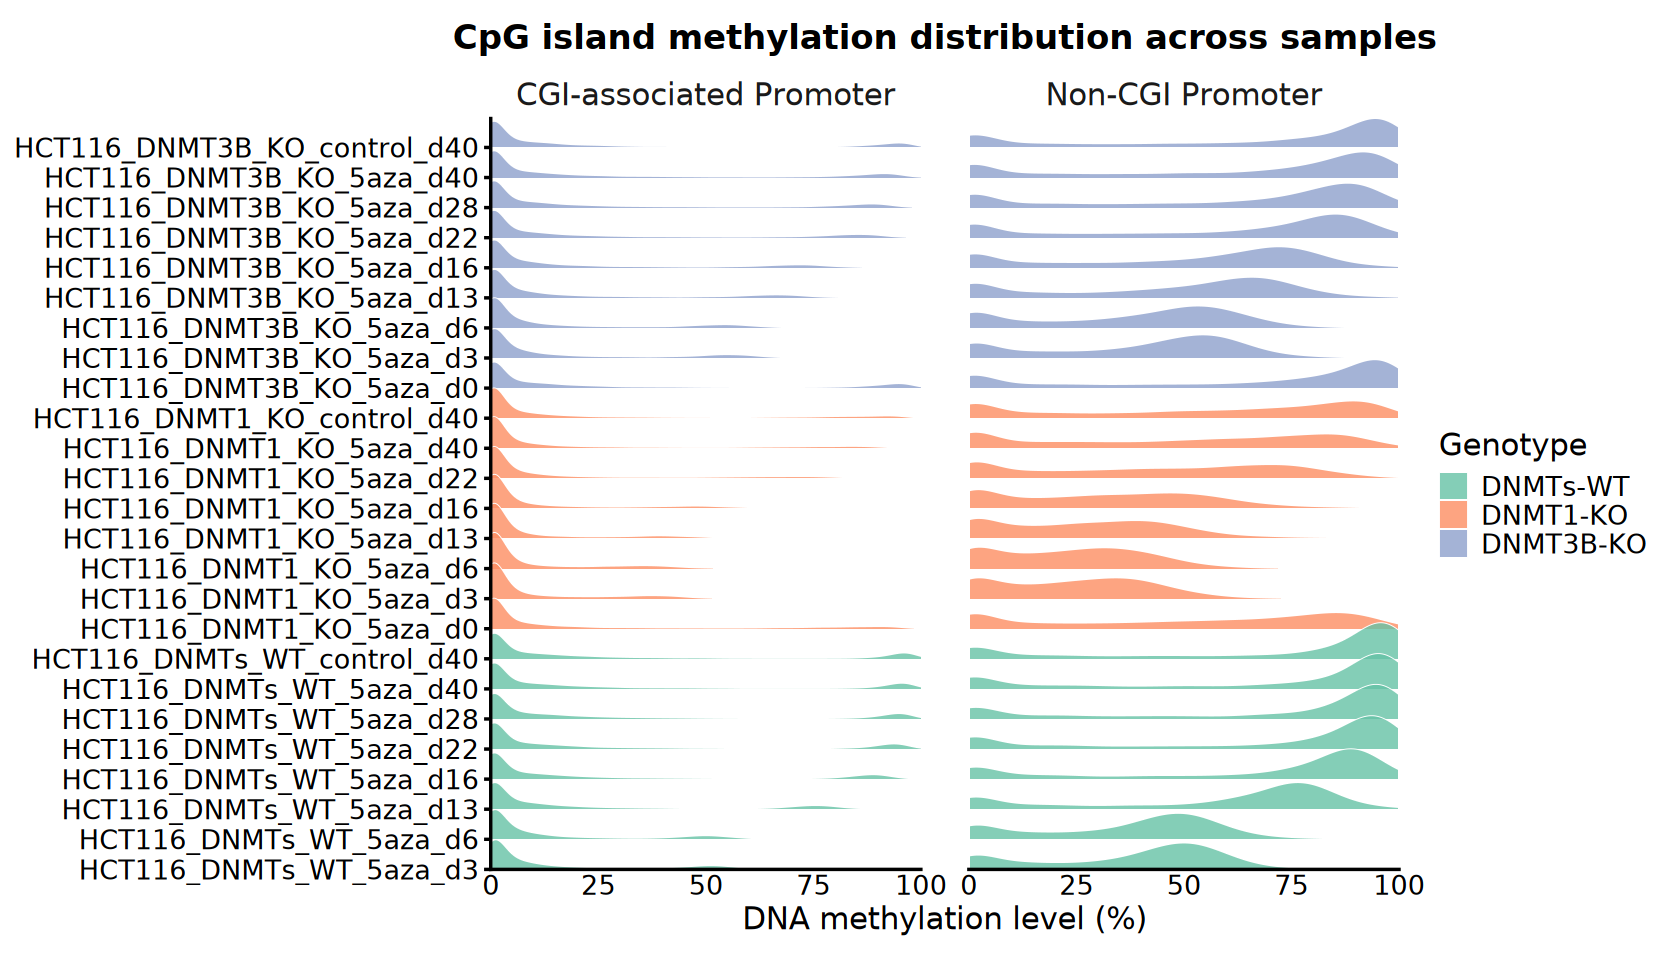

In [38]:
options(repr.plot.width = 14, repr.plot.height = 8)

ggplot(plot_df, aes(x = meth, y = sample)) +
    geom_density_ridges(
            aes(fill = Group), scale = 1.2, rel_min_height = 0.01, 
            alpha = 0.8, color = "white", linewidth = 0.2) +
    facet_wrap(~ CGI_status, labeller = labeller(
        CGI_status = c(
            "CGI" = "CGI-associated Promoter",
            "non_CGI" = "Non-CGI Promoter"))) +
    scale_x_continuous(limits = c(0, 100), expand = c(0, 0)) +
    scale_y_discrete(expand = c(0, 0)) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG island methylation distribution across samples",
        x = "DNA methylation level (%)", y = NULL, 
        fill = "Genotype") +
    theme_classic(base_size = 16) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing = unit(2, "lines"),
        strip.text = element_text(size = 18),
        strip.background = element_blank(), 
        strip.placement = "outside",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16),
        axis.ticks.x = element_blank())

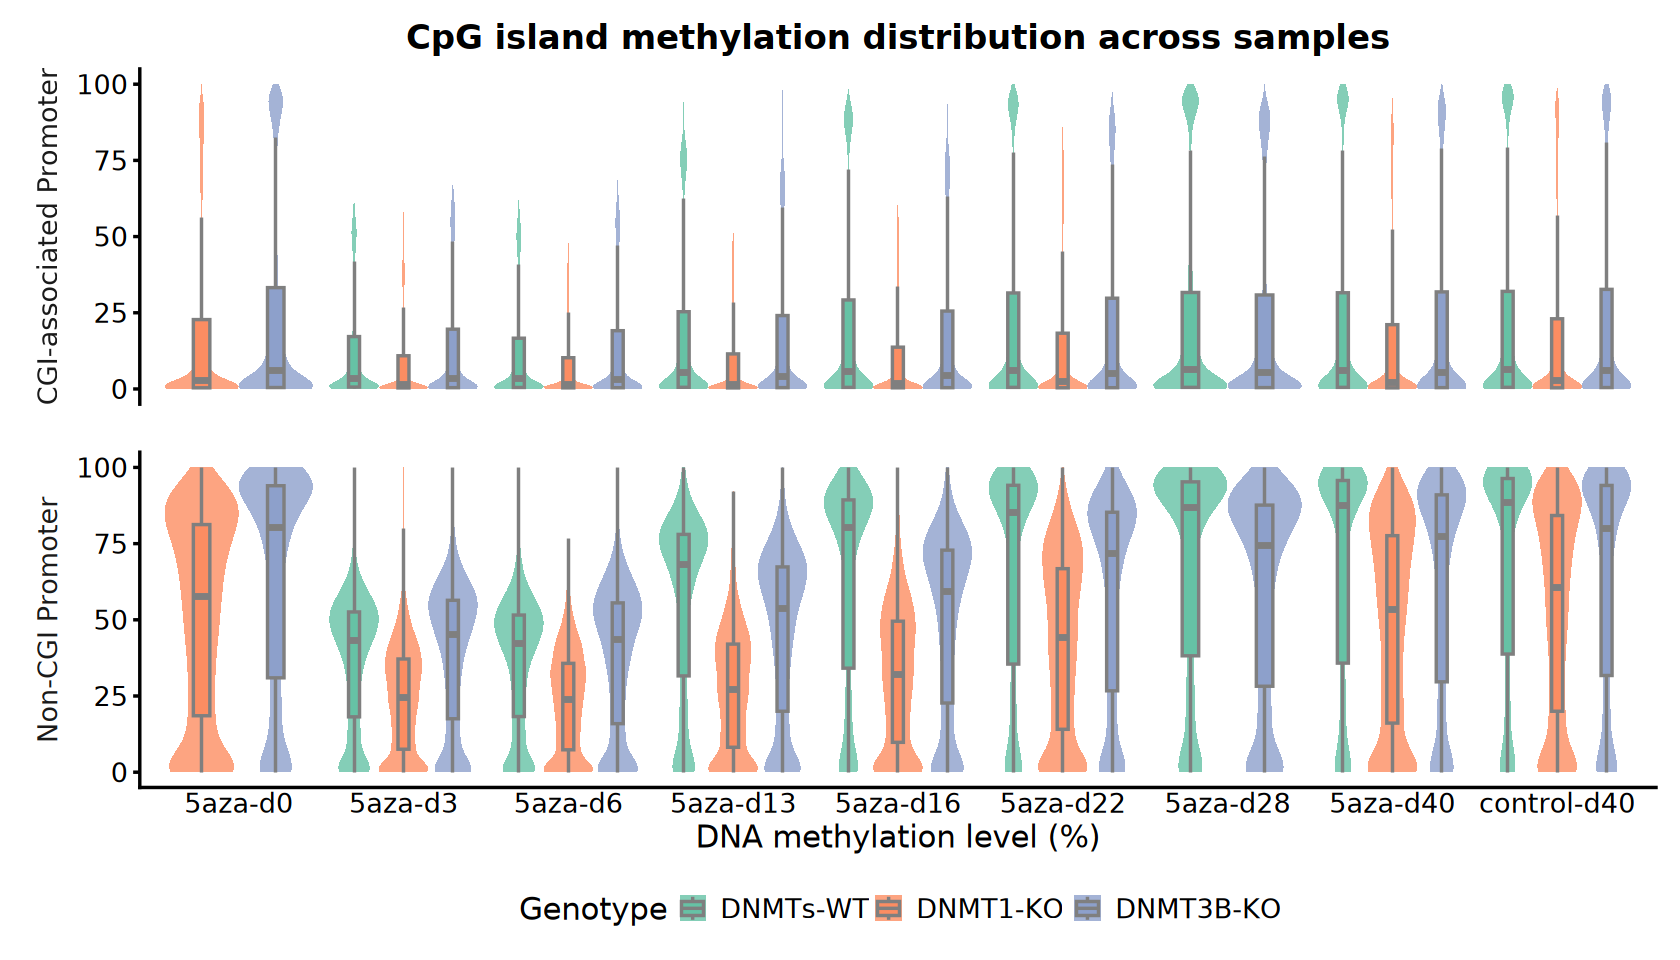

In [39]:
options(repr.plot.width = 14, repr.plot.height = 8)

ggplot(plot_df, aes(x = Condition, y = meth, fill = Group)) +
    geom_violin(
        trim = TRUE, scale = "width", color = NA, alpha = 0.8) +
    geom_boxplot(
        width = 0.2, outlier.shape = NA, color = "grey50",
        position = position_dodge(width = 0.9)) +
    facet_wrap(~ CGI_status, ncol = 1, strip.position = "left",
        labeller = labeller(CGI_status = c(
            "CGI" = "CGI-associated Promoter",
            "non_CGI" = "Non-CGI Promoter"))) +
    scale_color_brewer(palette = "Set2") +
    scale_fill_brewer(palette = "Set2") +
    labs(
        title = "CpG island methylation distribution across samples",
        x = "DNA methylation level (%)", y = NULL, 
        fill = "Genotype") +
    theme_classic(base_size = 16) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing = unit(2, "lines"),
        strip.text = element_text(size = 16),
        strip.background = element_blank(), 
        strip.placement = "outside",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16),
        axis.ticks.x = element_blank())

## 6). DNAm Distribution

In [40]:
gene <- genes(txdb)
promoter <- promoters(gene, upstream = 2000, downstream = 500)
downstream <- flank(gene, width = 2000, start = FALSE)

exon <- exonsBy(txdb, by = "gene")
intron <- intronsByTranscript(txdb)

utr5 <- fiveUTRsByTranscript(txdb)
cds <- cdsBy(txdb, by = "gene")
utr3 <- threeUTRsByTranscript(txdb)

gap <- c(gene, promoter, downstream) |> unstrand() |> gaps()
intergenic <- gap[strand(gap) == "*"]

  2169 genes were dropped because they have exons located on both strands of
  the same reference sequence or on more than one reference sequence, so cannot
  be represented by a single genomic range.
  Use 'single.strand.genes.only=FALSE' to get all the genes in a GRangesList
  object, or use suppressMessages() to suppress this message.

Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
“GRanges object contains 8 out-of-bound ranges located on sequences
  chr4_GL000257v2_alt, chr16_KI270728v1_random, chr22_KI270731v1_random,
  chr3_GL000221v1_random, chr1_KI270706v1_random, chr16_GL383556v1_alt, and
  chrUn_KI270748v1. Note that ranges located on a sequence whose length is
  unknown (NA) or on a circular sequence are not considered out-of-bound (use
  seqlengths() and isCircular() to get the lengths and circularity flags of the
  underlying sequences). You can use trim() to trim these ranges. See
  ?`trim,GenomicRanges-method` for more information.”
Warning messa

In [41]:
# CGI shore = ±2kb around CGI excluding CGI
# CGI shelf = 2–4kb around CGI excluding 0–2kb, CGI
cgi_2kb <- resize(CGI, width = width(CGI) + 4000, fix = "center")
cgi_shore <- setdiff(cgi_2kb, CGI)
cgi_4kb <- resize(CGI, width = width(CGI) + 8000, fix = "center")
cgi_shelf <- setdiff(cgi_4kb, cgi_2kb)

In [42]:
region_list <- list(
    CGI = CGI, CGI_Shore = cgi_shore, CGI_Shelf = cgi_shelf,
    Promoter = promoter, Exon = unlist(exon), Intron = unlist(intron),
    FiveUTR = unlist(utr5), CDS = unlist(cds), ThreeUTR = unlist(utr3),
    Downstream = downstream, Intergenic = intergenic
)

In [43]:
get_region_data <- function(
    gr, region_list, method = c("mean", "ratio"), 
    meth_col = "meth", numCs_col = "numCs", numTs_col = "numTs") {

    method <- match.arg(method)

    map_dfr(names(region_list), function(idx) {
        hits <- findOverlaps(gr, region_list[[idx]], ignore.strand = TRUE)
        sub_gr <- gr[queryHits(hits)]

        if (method == "mean") {
            vals <- mcols(sub_gr)[[meth_col]]
            mean <- mean(vals, na.rm = TRUE)
        } else if (method == "ratio") {
            numCs <- mcols(sub_gr)[[numCs_col]]
            numTs <- mcols(sub_gr)[[numTs_col]]

            sumCs <- sum(numCs, na.rm = TRUE)
            sumTs <- sum(numTs, na.rm = TRUE)
            mean <- sumCs / (sumCs + sumTs) * 100
        }
        tibble(region = idx, numCpG = length(sub_gr), mean = mean)
    })
}

In [44]:
meth_df <- imap_dfr(meth_list, function(gr, sample_id) {
    get_region_data(
        gr = gr, region_list = region_list, method = "mean", 
        meth_col = "meth")
}, .id = "sample") |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample") |>
    mutate(region = factor(region, levels = names(region_list))) |>
    mutate(sample = factor(sample, levels = names(meth_list)))

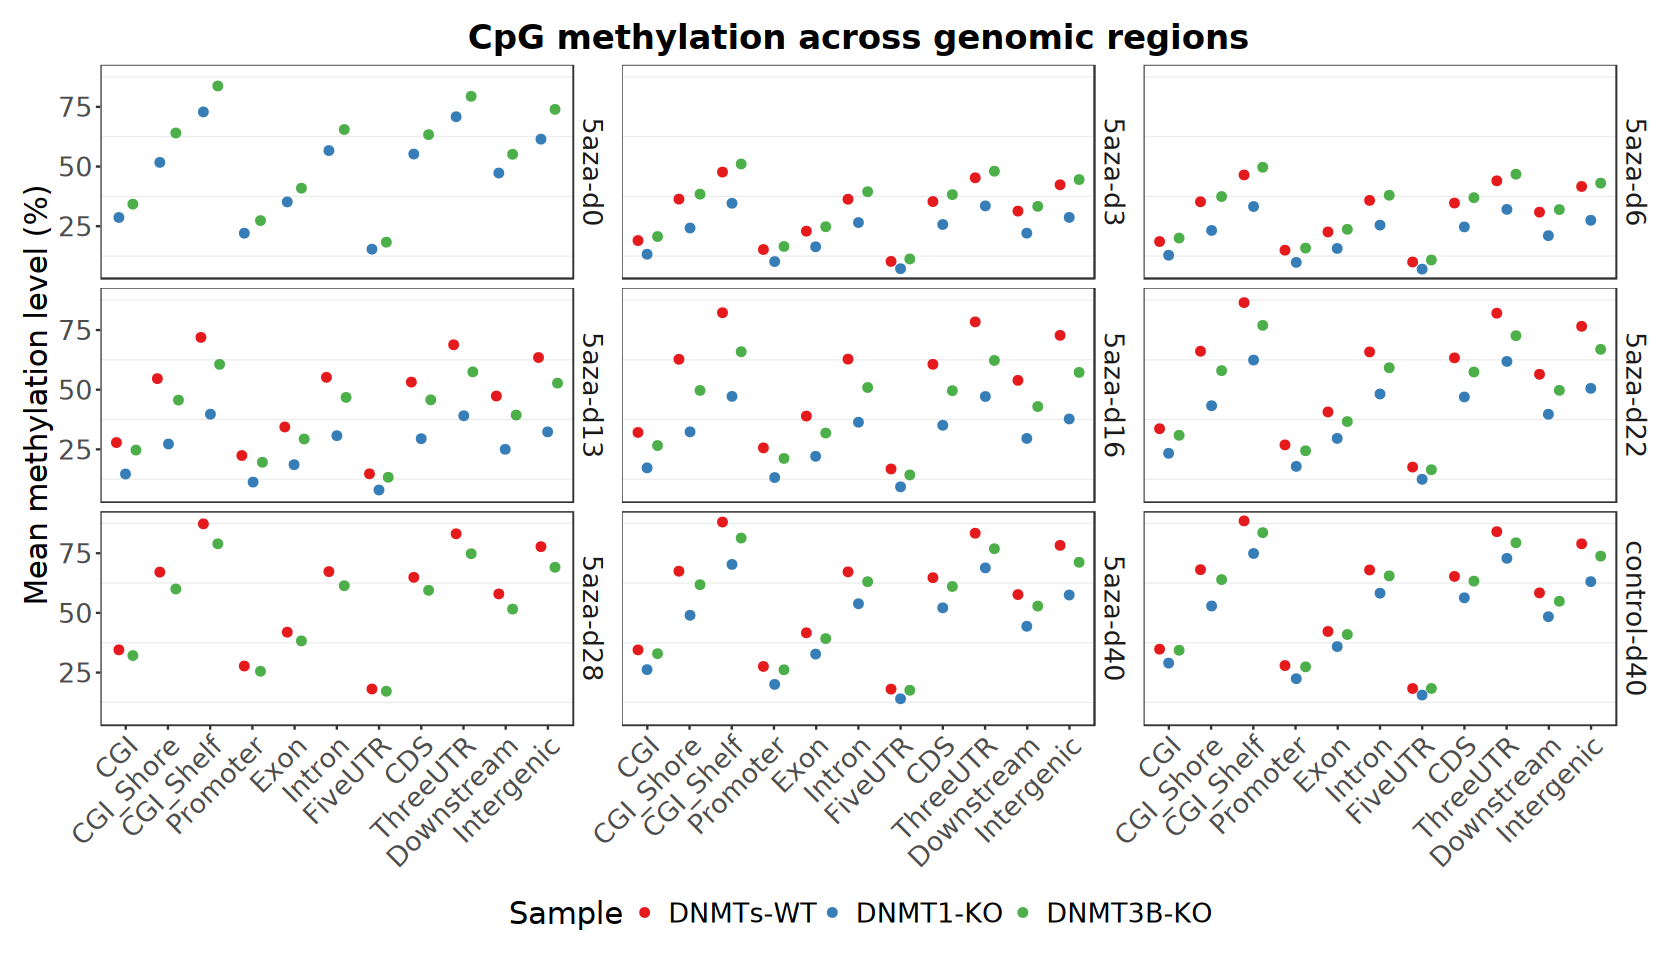

In [45]:
options(repr.plot.width = 14, repr.plot.height = 8)

ggplot(meth_df, aes(x = region, y = mean)) +
    geom_point(
        aes(color = Group), 
        position = position_jitterdodge(
            jitter.width = 0.1, dodge.width = 0.7), 
        size = 2, alpha = 1) +
    facet_wrap(~ Condition, ncol = 3, strip.position = "right") +
    # ggthemes::scale_color_tableau(palette = "Tableau 20") +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "CpG methylation across genomic regions", 
        x = NULL, y = "Mean methylation level (%)", 
        color = "Sample") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.grid.major = element_blank(),
        strip.text = element_text(size = 16),
        strip.background = element_blank(), 
        strip.placement = "outside",
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 16, angle = 45, vjust = 1, hjust = 1),
        axis.text.y = element_text(size = 16))

# * Reference